<a href="https://colab.research.google.com/github/Campelomiranda/projetoanoletivo/blob/claude%2Fvisual-schema-interaction-8irhhq/data-pipeline/notebooks/CityLens_rodar_no_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CityLens · Sorocaba — Pipeline no Google Colab

**Como usar (não precisa instalar nada no seu PC):**
1. No menu de cima: **Ambiente de execução → Executar tudo** (ou `Ctrl+F9`).
2. Espere ~2–4 min. No fim aparece o **mapa das 6 zonas** e uma tabela.

Este notebook baixa a malha de setores censitários do **IBGE** (via `geobr`),
descobre a posição de cada bairro pelo **OpenStreetMap** e atribui cada setor à
**zona do bairro mais próximo**. As 6 zonas são as oficiais do zoneamento da
Prefeitura/Urbes. Regra do projeto: **não inventar dado** — bairro que não for
encontrado é avisado e ignorado, nunca chutado.


In [1]:
# 1) Instala as bibliotecas (só nesta sessão do Colab)
!pip -q install geobr geopandas matplotlib requests 2>/dev/null
print("Bibliotecas prontas.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.0/53.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.5/21.5 MB 43.6 MB/s eta 0:00:00
Bibliotecas prontas.


In [2]:
# 2) As 6 zonas oficiais e seus bairros (transcritos do mapa oficial)
ZONAS = {
    "centro": {
        "nome": "Centro",
        "bairros": [
            "Centro"
        ]
    },
    "norte": {
        "nome": "Zona Norte",
        "bairros": [
            "Jardim Botucatu",
            "Jardim Maria Eugênia",
            "Parque Laranjeiras",
            "Jardim Guaíba",
            "Jardim São Guilherme",
            "Jardim Santa Marina",
            "Parque São Bento",
            "Jardim Novo Horizonte",
            "Jardim Maria Antônia Prado",
            "Jardim Guadalupe",
            "Vila Nova Sorocaba",
            "Vila Angélica",
            "Jardim Húngaros",
            "Jardim Brasilândia",
            "Vila Fiori",
            "Jardim Maria do Carmo",
            "Vila Gabriel",
            "Vila Progresso",
            "Vila Porto",
            "Vila Rica",
            "Parque Vitória Régia",
            "Retiro São João",
            "Jardim Iguatemi",
            "Jardim Morumbi",
            "Jardim Leocádia",
            "Vila Cardoso",
            "Vila Barão",
            "Vila Nova Esperança",
            "Jardim Zulmira",
            "Jardim Simus",
            "Jardim Vera Cruz",
            "Santa Terezinha",
            "Vila Trujillo",
            "Vila Carvalho",
            "Vila Santana",
            "Jardim Santa Rosália"
        ]
    },
    "oeste": {
        "nome": "Zona Oeste",
        "bairros": [
            "Jardim Santa Bárbara",
            "Júlio de Mesquita Filho",
            "Jardim Wanel Ville",
            "Parque Esmeralda",
            "Jardim Ouro Fino",
            "Parque Ouro Fino",
            "Parque Manchester",
            "Central Parque",
            "Largo do Divino",
            "Jardim São Paulo"
        ]
    },
    "sul": {
        "nome": "Zona Sul",
        "bairros": [
            "Vila Jardini",
            "Jardim Magnólia",
            "Jardim Paulistano",
            "Jardim Europa",
            "Jardim dos Estados",
            "Jardim América",
            "Jardim Portal da Colina",
            "Jardim Emília",
            "Jardim Sandra",
            "Parque da Biquinha",
            "Vila Assis",
            "Parque Água Vermelha",
            "Jardim Guadalajara",
            "Jardim São Carlos",
            "Parque Campolim"
        ]
    },
    "leste": {
        "nome": "Zona Leste",
        "bairros": [
            "Jardim Gonçalves",
            "Jardim Sol",
            "Jardim Bandeirantes",
            "Jardim Piratininga",
            "Jardim Granja",
            "Vila Haro",
            "Parque Três Meninos",
            "Vila Hortência",
            "Jardim Gutierres",
            "Jardim Prestes de Barros",
            "Vila Colorau",
            "Vila Barcelona",
            "Jardim Parada do Alto"
        ]
    },
    "industrial": {
        "nome": "Zona Industrial",
        "bairros": [
            "Aparecidinha",
            "Brigadeiro Tobias",
            "Alto da Boa Vista",
            "Parque Chico Mendes"
        ]
    }
}

import math, time, json, requests

def dist_km(lon1, lat1, lon2, lat2):
    """Distância aproximada (equiretangular) em km — ótima em escala de cidade."""
    R = 6371.0
    x = math.radians(lon2 - lon1) * math.cos(math.radians((lat1 + lat2)/2))
    y = math.radians(lat2 - lat1)
    return R * math.hypot(x, y)

def atribuir_por_proximidade(setores_xy, pontos):
    """Cada setor (id, lon, lat) recebe a zona do bairro mais próximo."""
    out = []
    for sid, slon, slat in setores_xy:
        melhor = None
        for zona, bairro, blon, blat in pontos:
            d = dist_km(slon, slat, blon, blat)
            if melhor is None or d < melhor[0]:
                melhor = (d, zona, bairro)
        out.append({"id": sid, "zona": melhor[1], "bairro": melhor[2],
                    "dist_km": round(melhor[0], 3)})
    return out

print("Funções de recorte carregadas.")

Funções de recorte carregadas.


In [3]:
# 3) Baixa a malha de setores censitários de Sorocaba (IBGE, via geobr)
import geobr, warnings
warnings.filterwarnings("ignore")
COD_SOROCABA = 3552205
try:
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022,
                                      simplified=False, showProgress=False)
except TypeError:
    # versões diferentes do geobr usam nomes de parâmetro distintos
    setores = geobr.read_census_tract(code_tract=COD_SOROCABA, year=2022)
setores = setores.to_crs(4326)
col_id = next((c for c in ["code_tract","CD_SETOR","CD_GEOCODI"] if c in setores.columns),
              setores.columns[0])
setores["CD_SETOR"] = setores[col_id].astype(str)
print(f"Setores de Sorocaba: {len(setores):,}")
setores.head(3)

censustracts_2022_simplified.parquet: 100%|██████████| 381M/381M [00:03<00:00, 99.6MB/s]


Setores de Sorocaba: 1,148


,code_tract,code_muni,name_muni,code_neighborhood,name_neighborhood,code_district,name_district,code_subdistrict,name_subdistrict,code_weighting,zone,code_state,abbrev_state,name_state,code_region,name_region,year,geometry,CD_SETOR
0,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.4558 -23.4985, -47.4569 -2...",355220505000001.0
1,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45252 -23.50157, -47.45274...",355220505000002.0
2,3.552205e+14,3552205.0,Sorocaba,NaN,None,355220505.0,Sorocaba,3.552205e+10,None,3.552205e+09,urbano,35.0,SP,São Paulo,3.0,Sudeste,2022.0,"MULTIPOLYGON (((-47.45667 -23.49986, -47.45878...",355220505000003.0


In [4]:
# 4) Descobre a posição (lat/lon) de cada bairro pelo OpenStreetMap (Nominatim)
CACHE = "/content/geocode_bairros.json"
try:
    cache = json.load(open(CACHE, encoding="utf-8"))
except Exception:
    cache = {}

headers = {"User-Agent": "CityLens-Sorocaba/1.0 (projeto escolar)"}
pontos, faltas = [], []
for zona, z in ZONAS.items():
    for bairro in z["bairros"]:
        chave = f"{bairro}|Sorocaba|SP"
        if chave not in cache:
            q = f"{bairro}, Sorocaba, SP, Brasil"
            try:
                r = requests.get("https://nominatim.openstreetmap.org/search",
                                 params={"q": q, "format": "json", "limit": 1,
                                         "countrycodes": "br"},
                                 headers=headers, timeout=25)
                js = r.json()
                cache[chave] = [float(js[0]["lon"]), float(js[0]["lat"])] if js else None
            except Exception as e:
                print("Erro de rede ao geocodificar", bairro, "->", e)
                cache[chave] = None
            json.dump(cache, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)
            time.sleep(1.1)   # política do Nominatim: no máx. 1 pedido por segundo
        coord = cache[chave]
        (pontos if coord else faltas).append(
            (zona, bairro, coord[0], coord[1]) if coord else (zona, bairro))

print(f"Bairros localizados: {len(pontos)} | não encontrados: {len(faltas)}")
if faltas:
    print("Ignorados (não inventamos posição):",
          ", ".join(f"{b} [{ZONAS[z]['nome']}]" for z, b in faltas))
zonas_com_ponto = {p[0] for p in pontos}
vazias = [ZONAS[z]["nome"] for z in ZONAS if z not in zonas_com_ponto]
assert not vazias, f"Zona sem nenhum bairro localizado: {vazias} — confira os nomes."

Bairros localizados: 76 | não encontrados: 3
Ignorados (não inventamos posição): Jardim Húngaros [Zona Norte], Vila Cardoso [Zona Norte], Jardim Magnólia [Zona Sul]


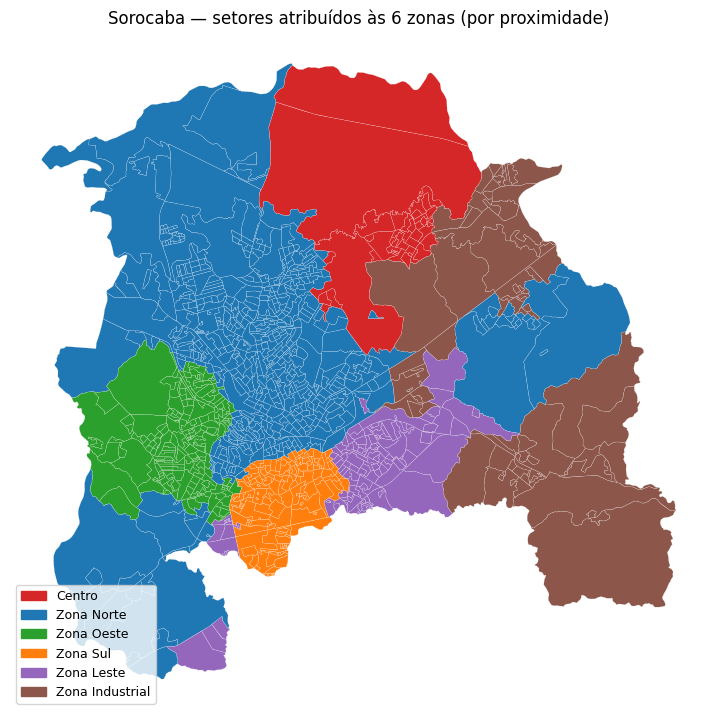


Setores por zona:
  Centro              43
  Zona Norte         580
  Zona Oeste         189
  Zona Sul           142
  Zona Leste         121
  Zona Industrial     73

CSV salvo em /content/setores_por_zona.csv


In [7]:
# 5) Atribui cada setor à sua zona e desenha o mapa
cent = setores.to_crs(3857).geometry.centroid.to_crs(4326)
setores_xy = [(cd, p.x, p.y) for cd, p in zip(setores["CD_SETOR"], cent)]
atrib = atribuir_por_proximidade(setores_xy, pontos)

zona_de = {a["id"]: a["zona"] for a in atrib}
ordem = list(ZONAS.keys())
setores["zona"] = setores["CD_SETOR"].map(zona_de)
setores["_zi"] = setores["zona"].map({z: i for i, z in enumerate(ordem)})

import matplotlib.pyplot as plt, matplotlib.patches as mpatches
fig, ax = plt.subplots(figsize=(9, 9))
# cores fixas por zona: a mesma cor no mapa e na legenda
CORES = {"centro": "#d62728", "norte": "#1f77b4", "oeste": "#2ca02c",
         "sul": "#ff7f0e", "leste": "#9467bd", "industrial": "#8c564b"}
setores.plot(color=setores["zona"].map(CORES).fillna("#cccccc"),
             linewidth=0.12, edgecolor="white", ax=ax)
ax.legend(handles=[mpatches.Patch(color=CORES[z], label=ZONAS[z]["nome"])
                   for z in ordem],
          loc="lower left", fontsize=9, frameon=True)
ax.set_title("Sorocaba — setores atribuídos às 6 zonas (por proximidade)")
ax.set_axis_off(); plt.show()

# tabela: quantos setores por zona
from collections import Counter
c = Counter(a["zona"] for a in atrib)
print("\nSetores por zona:")
for z in ordem:
    print(f"  {ZONAS[z]['nome']:<16} {c.get(z,0):>5}")

# salva o CSV (baixe pelo painel de Arquivos à esquerda, se quiser)
import csv
with open("/content/setores_por_zona.csv", "w", encoding="utf-8", newline="") as f:
    w = csv.writer(f); w.writerow(["CD_SETOR","zona","bairro_mais_proximo","dist_km"])
    for a in atrib: w.writerow([a["id"], a["zona"], a["bairro"], a["dist_km"]])
print("\nCSV salvo em /content/setores_por_zona.csv")

In [9]:
# 6) Diagnóstico: bairros longe do "miolo" da própria zona (possível erro de geocodificação)
import statistics as st
for z in ZONAS:
    pz = [p for p in pontos if p[0] == z]
    mlo = st.median(p[2] for p in pz); mla = st.median(p[3] for p in pz)
    print(f"{ZONAS[z]['nome']}: {len(pz)} pts, miolo lon={mlo:.4f} lat={mla:.4f}")
    for _, b, lo, la in pz:
        d = dist_km(lo, la, mlo, mla)
        if d > 3.5:
            print(f"   SUSPEITO {b}: lon={lo:.4f} lat={la:.4f} ({d:.1f} km do miolo)")

Centro: 1 pts, miolo lon=-47.4415 lat=-23.4345
Zona Norte: 34 pts, miolo lon=-47.4733 lat=-23.4730
   SUSPEITO Jardim Botucatu: lon=-47.5105 lat=-23.4550 (4.3 km do miolo)
   SUSPEITO Parque São Bento: lon=-47.5062 lat=-23.4320 (5.7 km do miolo)
   SUSPEITO Vila Porto: lon=-47.3764 lat=-23.4504 (10.2 km do miolo)
   SUSPEITO Vila Rica: lon=-47.5030 lat=-23.5292 (6.9 km do miolo)
   SUSPEITO Parque Vitória Régia: lon=-47.4620 lat=-23.4308 (4.8 km do miolo)
   SUSPEITO Jardim Iguatemi: lon=-47.4368 lat=-23.4694 (3.7 km do miolo)
   SUSPEITO Jardim Morumbi: lon=-47.4347 lat=-23.4719 (3.9 km do miolo)
   SUSPEITO Jardim Leocádia: lon=-47.4384 lat=-23.4713 (3.6 km do miolo)
   SUSPEITO Jardim Simus: lon=-47.4943 lat=-23.5028 (3.9 km do miolo)
   SUSPEITO Jardim Vera Cruz: lon=-47.4919 lat=-23.5081 (4.3 km do miolo)
Zona Oeste: 10 pts, miolo lon=-47.5047 lat=-23.5016
Zona Sul: 14 pts, miolo lon=-47.4687 lat=-23.5182
Zona Leste: 13 pts, miolo lon=-47.4319 lat=-23.5063
   SUSPEITO Jardim Sol: 